# Experiment 5: DiagScale during continued pretraining

Forty-eight runs adapt only query-scaling parameters across credit tables: two model families, three adapter learning rates, four dataset partitions and two tasks. Original backbone weights stay unchanged. The objective is transfer to excluded tables, rather than target-table fine-tuning.

## 0. Evidence and scope

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
style.apply()
from src.visualize import adapter_study as ds, publication as pub, pilots as pv
sink = FigureSaver('experiment5/01_training')
report = cp.NotebookReport('Experiment 5: DiagScale during continued pretraining', sink=sink)
print(source_description())
report.add('0. Evidence and scope', source_description())
runs = [cp.load_campaign(5, track) for track in ('pd', 'lgd')]

DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


## 1. Adapter recipe and training coverage

,setting,value
0,Optimized parameters,Zero-centered query-scale deltas only; origina...
1,Training,Cross-table CPT; target table excluded from ch...
2,Grid,2 bases × 3 adapter rates × 4 dataset partitio...
3,Adapter rates,"0.0001, 0.001, 0.03"
4,Episode cap,8192
5,Precision,FP32; TabICL original/adapter inference both d...
6,Budget,"10,000 successful updates; seed 42"
7,Regularization,AdamW decay on zero-centered deltas; no L2-SP
8,Parameter movement,RMS query-scale delta; not relative backbone-w...
9,Interpretation,Recipe-level comparison against the base; not ...


,evidence,records,origin
0,Planned trials,24,Config; not scheduler state
1,Completed trials,23,DATA manifests
2,Epoch rows,18888,Project training diagnostics
3,Milestone rows,144,Project trajectory diagnostics
4,Benchmark folds,0,Project final evaluation


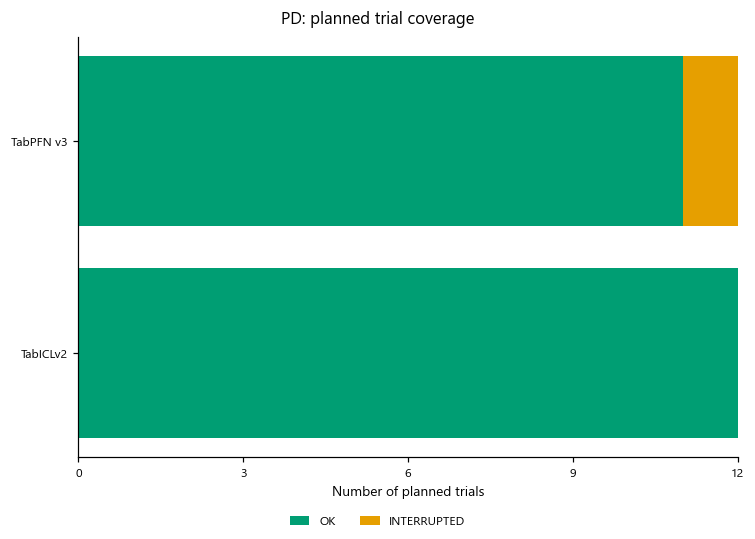

PD. Recorded status of 24 planned PD trials by base model. PENDING denotes no manifest outcome and can include currently running or queued jobs. INTERRUPTED denotes saved progress, not a numerical failure. This figure does not query the scheduler.

,setting,value
0,Optimized parameters,Zero-centered query-scale deltas only; origina...
1,Training,Cross-table CPT; target table excluded from ch...
2,Grid,2 bases × 3 adapter rates × 4 dataset partitio...
3,Adapter rates,"0.0001, 0.001, 0.03"
4,Episode cap,8192
5,Precision,FP32; TabICL original/adapter inference both d...
6,Budget,"10,000 successful updates; seed 42"
7,Regularization,AdamW decay on zero-centered deltas; no L2-SP
8,Parameter movement,RMS query-scale delta; not relative backbone-w...
9,Interpretation,Recipe-level comparison against the base; not ...


,evidence,records,origin
0,Planned trials,24,Config; not scheduler state
1,Completed trials,9,DATA manifests
2,Epoch rows,15012,Project training diagnostics
3,Milestone rows,54,Project trajectory diagnostics
4,Benchmark folds,0,Project final evaluation


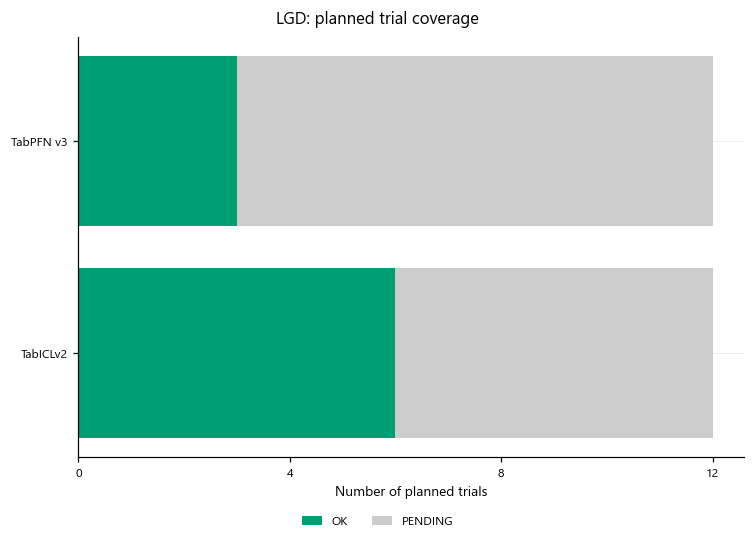

LGD. Recorded status of 24 planned LGD trials by base model. PENDING denotes no manifest outcome and can include currently running or queued jobs. INTERRUPTED denotes saved progress, not a numerical failure. This figure does not query the scheduler.

In [2]:
for run in runs:
    report.table(run.track.upper()+' protocol', ds.protocol_table(run))
    report.table(run.track.upper()+' evidence', pub.availability(run))
    cp.show(sink, cp.plot_coverage(run), track=run.track)
report.add('1. Adapter recipe and training coverage', 'Only optimizer-selected scale deltas are updated. TabICL can retain backbone autograd flags without placing backbone tensors in the optimizer. Completed training does not establish completed evaluation.')

## 2. Loss, gradients and query-scale movement

Each model receives a compact four-panel dashboard. Curves average all four training-dataset partitions at each adapter rate. Loss stays on its native architecture-specific scale. RMS adapter movement is measured from identity scaling; relative movement from zero-valued deltas is undefined.

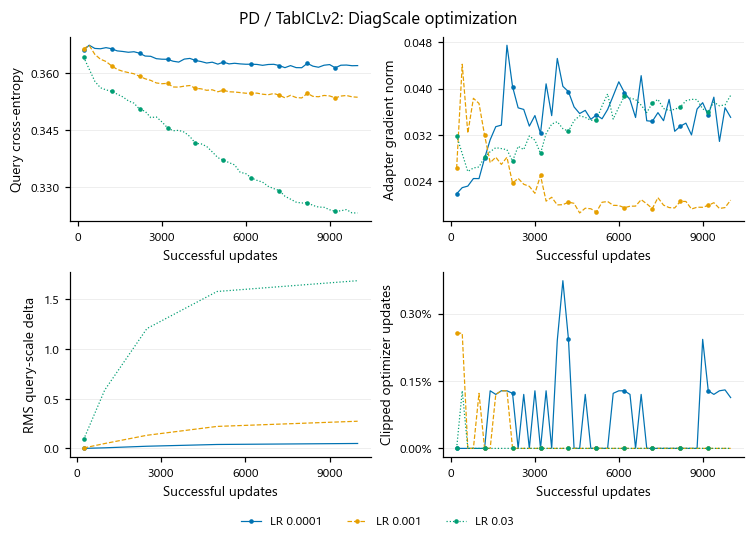

PD. Mean diagnostics across all four dataset partitions at each adapter rate. Lines connect recorded summaries, with periodically spaced markers; a missing partition leaves a gap. Data loss is the native query objective; incomplete table-coverage epochs are excluded. Gradient diagnostics concern optimizer-selected query-scale deltas. Movement is RMS delta from the identity scaling, not a relative change from zero-valued adapter parameters.

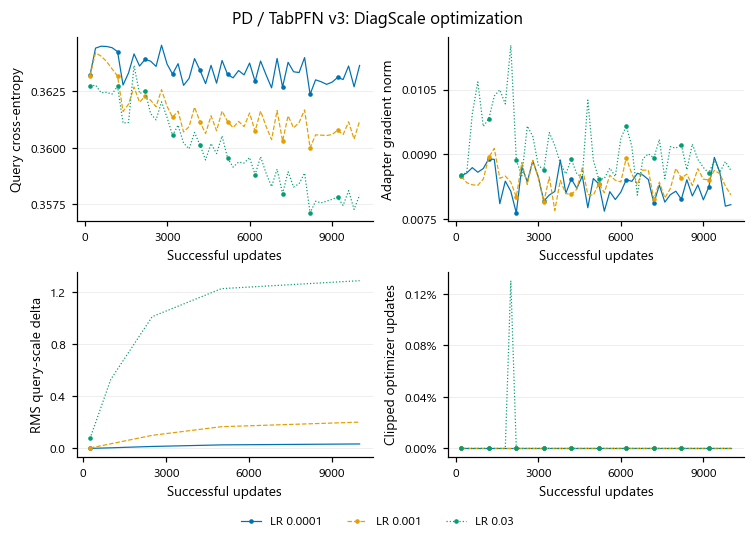

PD. Mean diagnostics across all four dataset partitions at each adapter rate. Lines connect recorded summaries, with periodically spaced markers; a missing partition leaves a gap. Data loss is the native query objective; incomplete table-coverage epochs are excluded. Gradient diagnostics concern optimizer-selected query-scale deltas. Movement is RMS delta from the identity scaling, not a relative change from zero-valued adapter parameters.

,base,learning_rate,l2sp_lambda,frozen,sampling,partition,seed,epochs,nonfinite_diagnostics,peak_epoch_gradient,peak_epoch_clipped_fraction,peak_l2sp_penalty,amp_skips,data_skips,peak_weight_drift
0,TabPFN v3,0.0001,0.0,False,one_sample,0,42,770,0,0.024910,0.000000,0.0,0,0,0.032038
1,TabPFN v3,0.0010,0.0,False,one_sample,0,42,770,0,0.027955,0.000000,0.0,0,0,0.184803
2,TabPFN v3,0.0300,0.0,False,one_sample,0,42,770,0,0.045635,0.000000,0.0,0,0,1.263868
3,TabICLv2,0.0001,0.0,False,one_sample,0,42,770,0,0.414389,0.076923,0.0,0,0,0.038982
4,TabICLv2,0.0010,0.0,False,one_sample,0,42,770,0,0.099649,0.076923,0.0,0,0,0.275439
5,TabICLv2,0.0300,0.0,False,one_sample,0,42,770,0,0.090922,0.000000,0.0,0,0,1.640877
6,TabPFN v3,0.0001,0.0,False,one_sample,1,42,770,0,0.038443,0.000000,0.0,0,0,0.033577
7,TabPFN v3,0.0010,0.0,False,one_sample,1,42,770,0,0.034757,0.000000,0.0,0,0,0.199136
8,TabPFN v3,0.0300,0.0,False,one_sample,1,42,770,0,0.092207,0.000000,0.0,0,0,1.233613
9,TabICLv2,0.0001,0.0,False,one_sample,1,42,770,0,0.671533,0.076923,0.0,0,0,0.053894


,trial_name,base,learning_rate,l2sp_lambda,frozen,sampling,recorded_epochs,full_coverage_epochs,fullest_observed_tables,min_observed_tables,last_update,partial_coverage_epochs
0,cpt_diagscale_v1_s00_pd_tabicl-classifier-v2-2...,TabICLv2,0.0010,0.0,False,one_sample,770,769,13,3,10000,1
1,cpt_diagscale_v1_s00_pd_tabicl-classifier-v2-2...,TabICLv2,0.0001,0.0,False,one_sample,770,769,13,3,10000,1
2,cpt_diagscale_v1_s00_pd_tabicl-classifier-v2-2...,TabICLv2,0.0300,0.0,False,one_sample,770,769,13,3,10000,1
3,cpt_diagscale_v1_s00_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0010,0.0,False,one_sample,770,769,13,3,10000,1
4,cpt_diagscale_v1_s00_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0001,0.0,False,one_sample,770,769,13,3,10000,1
5,cpt_diagscale_v1_s00_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0300,0.0,False,one_sample,770,769,13,3,10000,1
6,cpt_diagscale_v1_s01_pd_tabicl-classifier-v2-2...,TabICLv2,0.0010,0.0,False,one_sample,770,769,13,3,10000,1
7,cpt_diagscale_v1_s01_pd_tabicl-classifier-v2-2...,TabICLv2,0.0001,0.0,False,one_sample,770,769,13,3,10000,1
8,cpt_diagscale_v1_s01_pd_tabicl-classifier-v2-2...,TabICLv2,0.0300,0.0,False,one_sample,770,769,13,3,10000,1
9,cpt_diagscale_v1_s01_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0010,0.0,False,one_sample,770,769,13,3,10000,1


,trial_name,successful_updates,train_loss,observed_tables,full_observed_tables,complete_pass,base,learning_rate,l2sp_lambda,frozen,sampling
0,cpt_diagscale_v1_s00_pd_tabicl-classifier-v2-2...,10000,0.326306,3,13,False,TabICLv2,0.0010,0.0,False,one_sample
1,cpt_diagscale_v1_s00_pd_tabicl-classifier-v2-2...,10000,0.333000,3,13,False,TabICLv2,0.0001,0.0,False,one_sample
2,cpt_diagscale_v1_s00_pd_tabicl-classifier-v2-2...,10000,0.330692,3,13,False,TabICLv2,0.0300,0.0,False,one_sample
3,cpt_diagscale_v1_s00_pd_tabpfn-v3-classifier-v...,10000,0.339759,3,13,False,TabPFN v3,0.0010,0.0,False,one_sample
4,cpt_diagscale_v1_s00_pd_tabpfn-v3-classifier-v...,10000,0.342360,3,13,False,TabPFN v3,0.0001,0.0,False,one_sample
5,cpt_diagscale_v1_s00_pd_tabpfn-v3-classifier-v...,10000,0.337792,3,13,False,TabPFN v3,0.0300,0.0,False,one_sample
6,cpt_diagscale_v1_s01_pd_tabicl-classifier-v2-2...,10000,0.323144,3,13,False,TabICLv2,0.0010,0.0,False,one_sample
7,cpt_diagscale_v1_s01_pd_tabicl-classifier-v2-2...,10000,0.334740,3,13,False,TabICLv2,0.0001,0.0,False,one_sample
8,cpt_diagscale_v1_s01_pd_tabicl-classifier-v2-2...,10000,0.276509,3,13,False,TabICLv2,0.0300,0.0,False,one_sample
9,cpt_diagscale_v1_s01_pd_tabpfn-v3-classifier-v...,10000,0.328744,3,13,False,TabPFN v3,0.0010,0.0,False,one_sample


No measurements available for this section yet.


,base,learning_rate,l2sp_lambda,frozen,sampling,partition,seed,epochs,nonfinite_diagnostics,peak_epoch_gradient,peak_epoch_clipped_fraction,peak_l2sp_penalty,amp_skips,data_skips,peak_weight_drift
0,TabICLv2,0.0001,0.0,False,one_sample,0,42,1667,0,0.019257,0.000000,0.0,0,0,0.056318
1,TabICLv2,0.0010,0.0,False,one_sample,0,42,1667,0,0.024280,0.000000,0.0,0,0,0.354603
2,TabICLv2,0.0300,0.0,False,one_sample,0,42,1667,0,0.038219,0.000000,0.0,0,0,2.086672
3,TabPFN v3,0.0001,0.0,False,one_sample,2,42,1667,0,0.323042,0.166667,0.0,0,0,0.084769
4,TabPFN v3,0.0010,0.0,False,one_sample,2,42,1667,0,0.321609,0.166667,0.0,0,0,0.392038
5,TabPFN v3,0.0300,0.0,False,one_sample,2,42,1667,0,0.446313,0.166667,0.0,0,0,2.028394
6,TabICLv2,0.0001,0.0,False,one_sample,2,42,1667,0,0.018754,0.000000,0.0,0,0,0.060955
7,TabICLv2,0.0010,0.0,False,one_sample,2,42,1667,0,0.022413,0.000000,0.0,0,0,0.355380
8,TabICLv2,0.0300,0.0,False,one_sample,2,42,1667,0,0.024929,0.000000,0.0,0,0,2.052335


,trial_name,base,learning_rate,l2sp_lambda,frozen,sampling,recorded_epochs,full_coverage_epochs,fullest_observed_tables,min_observed_tables,last_update,partial_coverage_epochs
0,cpt_diagscale_v1_s00_lgd_tabicl-regressor-v2-2...,TabICLv2,0.0010,0.0,False,one_sample,1667,1666,6,4,10000,1
1,cpt_diagscale_v1_s00_lgd_tabicl-regressor-v2-2...,TabICLv2,0.0001,0.0,False,one_sample,1667,1666,6,4,10000,1
2,cpt_diagscale_v1_s00_lgd_tabicl-regressor-v2-2...,TabICLv2,0.0300,0.0,False,one_sample,1667,1666,6,4,10000,1
3,cpt_diagscale_v1_s02_lgd_tabicl-regressor-v2-2...,TabICLv2,0.0010,0.0,False,one_sample,1667,1666,6,4,10000,1
4,cpt_diagscale_v1_s02_lgd_tabicl-regressor-v2-2...,TabICLv2,0.0001,0.0,False,one_sample,1667,1666,6,4,10000,1
5,cpt_diagscale_v1_s02_lgd_tabicl-regressor-v2-2...,TabICLv2,0.0300,0.0,False,one_sample,1667,1666,6,4,10000,1
6,cpt_diagscale_v1_s02_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0010,0.0,False,one_sample,1667,1666,6,4,10000,1
7,cpt_diagscale_v1_s02_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0001,0.0,False,one_sample,1667,1666,6,4,10000,1
8,cpt_diagscale_v1_s02_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0300,0.0,False,one_sample,1667,1666,6,4,10000,1


,trial_name,successful_updates,train_loss,observed_tables,full_observed_tables,complete_pass,base,learning_rate,l2sp_lambda,frozen,sampling
0,cpt_diagscale_v1_s00_lgd_tabicl-regressor-v2-2...,10000,0.130184,4,6,False,TabICLv2,0.0010,0.0,False,one_sample
1,cpt_diagscale_v1_s00_lgd_tabicl-regressor-v2-2...,10000,0.140958,4,6,False,TabICLv2,0.0001,0.0,False,one_sample
2,cpt_diagscale_v1_s00_lgd_tabicl-regressor-v2-2...,10000,0.107772,4,6,False,TabICLv2,0.0300,0.0,False,one_sample
3,cpt_diagscale_v1_s02_lgd_tabicl-regressor-v2-2...,10000,0.146599,4,6,False,TabICLv2,0.0010,0.0,False,one_sample
4,cpt_diagscale_v1_s02_lgd_tabicl-regressor-v2-2...,10000,0.154780,4,6,False,TabICLv2,0.0001,0.0,False,one_sample
5,cpt_diagscale_v1_s02_lgd_tabicl-regressor-v2-2...,10000,0.138729,4,6,False,TabICLv2,0.0300,0.0,False,one_sample
6,cpt_diagscale_v1_s02_lgd_tabpfn-v3-regressor-v...,10000,-0.038921,4,6,False,TabPFN v3,0.0010,0.0,False,one_sample
7,cpt_diagscale_v1_s02_lgd_tabpfn-v3-regressor-v...,10000,0.024929,4,6,False,TabPFN v3,0.0001,0.0,False,one_sample
8,cpt_diagscale_v1_s02_lgd_tabpfn-v3-regressor-v...,10000,-0.128984,4,6,False,TabPFN v3,0.0300,0.0,False,one_sample


In [3]:
for run in runs:
    cp.show(sink, ds.plot_optimization(run))
    report.table(run.track.upper()+' numerical health', pv.health_table(run))
    for label, table in cp.loss_coverage_tables(run).items():
        report.table(run.track.upper()+' '+label, table)
report.add('2. Loss, gradients and query-scale movement', 'Zero L2-SP is not plotted as an effect. AdamW decays zero-centered deltas. Clipping concerns adapter gradients in both classification and regression; unavailable measurements remain gaps.')

## 3. Credit transfer and non-credit retention

Monitor AUC for PD and R² for LGD at fixed milestones. These small-context monitors describe learning dynamics; they do not replace the final five-fold benchmark.

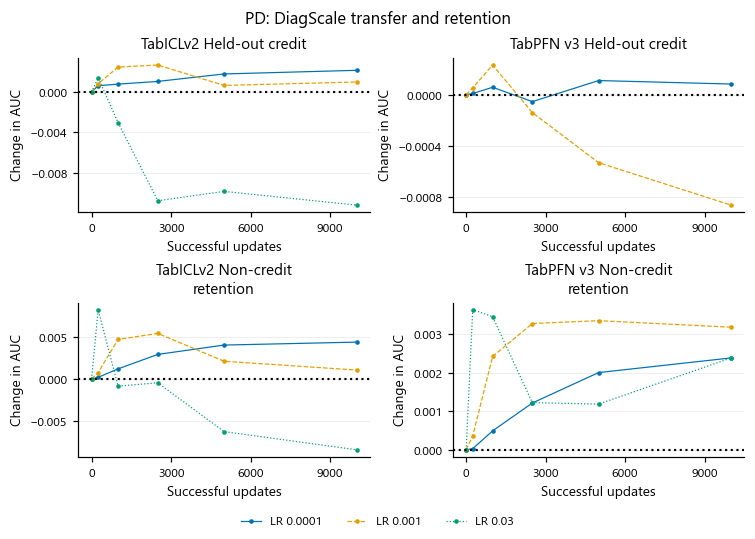

PD. Change in AUC from each table's update-zero score. Repeated non-credit partitions are averaged within table; tables receive equal weight. All planned partitions and the unchanged baseline table cohort are required at every milestone. These fixed-context training monitors are distinct from the final five-fold benchmark.

No measurements available for this section yet.


In [4]:
for run in runs:
    cp.show(sink, ds.plot_monitors(run))
report.add('3. Credit transfer and non-credit retention', 'Each table is paired with its own update-zero score. A complete baseline cohort and every planned partition are required. Repeated non-credit observations are averaged within table before equal-table aggregation.')

## 4. Applied schedule and computational cost

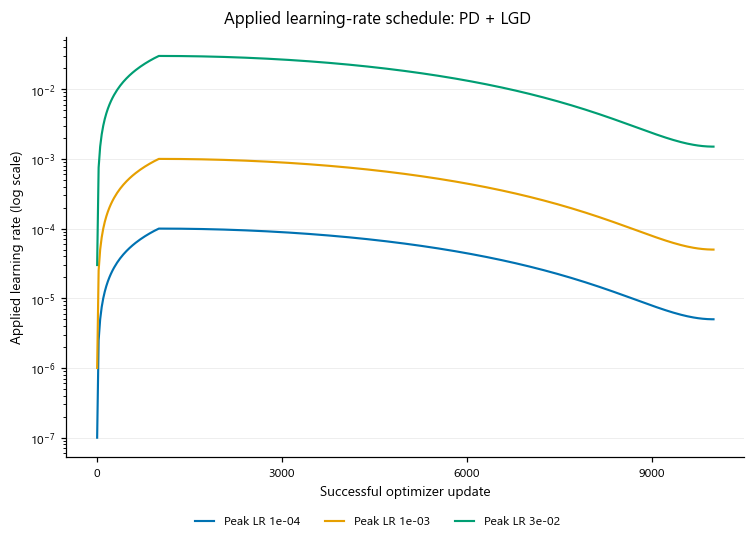

Learning rates evaluated from the recorded campaign configuration using the training scheduler. Each distinct peak-rate schedule is drawn once, pooling tasks only when budget, warmup and decay floor agree. The rate for update u is the scheduler value before that update (index u minus one). The first update has zero learning rate and is omitted from the logarithmic axis, but retained in the table. These are configured schedules; measured epoch-end rates and their sampling intervals are reported separately.

,trial_name,base,learning_rate,partition,status,optimizer_selected_params,total_params,rows_seen,elapsed_sec,gpu_hours,peak_gpu_gb,query_scale_delta_rms
0,cpt_diagscale_v1_s00_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0001,0,OK,13056,53166200,70788725,6168.156499,1.713377,39.133,0.032038
1,cpt_diagscale_v1_s00_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0010,0,OK,13056,53166200,70788725,6147.738720,1.707705,39.345,0.184803
2,cpt_diagscale_v1_s00_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0300,0,OK,13056,53166200,70788725,6169.156107,1.713654,39.133,1.263868
3,cpt_diagscale_v1_s00_pd_tabicl-classifier-v2-2...,TabICLv2,0.0001,0,OK,7296,27559554,70788725,4766.576668,1.324049,15.873,0.038982
4,cpt_diagscale_v1_s00_pd_tabicl-classifier-v2-2...,TabICLv2,0.0010,0,OK,7296,27559554,70788725,4770.898052,1.325249,15.873,0.275439
5,cpt_diagscale_v1_s00_pd_tabicl-classifier-v2-2...,TabICLv2,0.0300,0,OK,7296,27559554,70788725,4776.914145,1.326921,15.763,1.640877
6,cpt_diagscale_v1_s01_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0001,1,OK,13056,53166200,69239144,6049.478816,1.680411,39.771,0.033577
7,cpt_diagscale_v1_s01_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0010,1,OK,13056,53166200,69239144,6071.310221,1.686475,39.558,0.199136
8,cpt_diagscale_v1_s01_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0300,1,OK,13056,53166200,69239144,6096.050658,1.693347,39.771,1.233613
9,cpt_diagscale_v1_s01_pd_tabicl-classifier-v2-2...,TabICLv2,0.0001,1,OK,7296,27559554,69239144,4809.640543,1.336011,15.873,0.053894


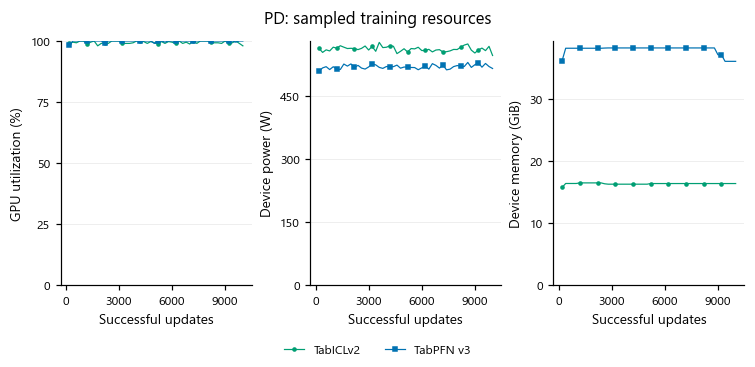

Device counters during training, summarized first by a within-trial window median, then by the median across observed trials. Recipes and adaptation modes are pooled; trial counts accompany every value. Axes start at zero, and utilization spans 0–100%, so small counter fluctuations are not magnified. Changing support can change these descriptive curves. Device samples are neither process-specific utilization nor integrated energy measurements. Missing counters remain gaps.

,trial_name,base,learning_rate,partition,status,optimizer_selected_params,total_params,rows_seen,elapsed_sec,gpu_hours,peak_gpu_gb,query_scale_delta_rms
0,cpt_diagscale_v1_s00_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0001,0,PENDING,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,cpt_diagscale_v1_s00_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0010,0,PENDING,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,cpt_diagscale_v1_s00_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0300,0,PENDING,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,cpt_diagscale_v1_s00_lgd_tabicl-regressor-v2-2...,TabICLv2,0.0001,0,OK,7296.0,28552287.0,40087565.0,2277.811915,0.632726,6.741,0.056318
4,cpt_diagscale_v1_s00_lgd_tabicl-regressor-v2-2...,TabICLv2,0.0010,0,OK,7296.0,28552287.0,40087565.0,2279.549649,0.633208,6.741,0.354603
5,cpt_diagscale_v1_s00_lgd_tabicl-regressor-v2-2...,TabICLv2,0.0300,0,OK,7296.0,28552287.0,40087565.0,2282.008839,0.633891,6.627,2.086672
6,cpt_diagscale_v1_s01_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0001,1,PENDING,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,cpt_diagscale_v1_s01_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0010,1,PENDING,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,cpt_diagscale_v1_s01_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0300,1,PENDING,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,cpt_diagscale_v1_s01_lgd_tabicl-regressor-v2-2...,TabICLv2,0.0001,1,PENDING,NaN,NaN,NaN,NaN,NaN,NaN,NaN


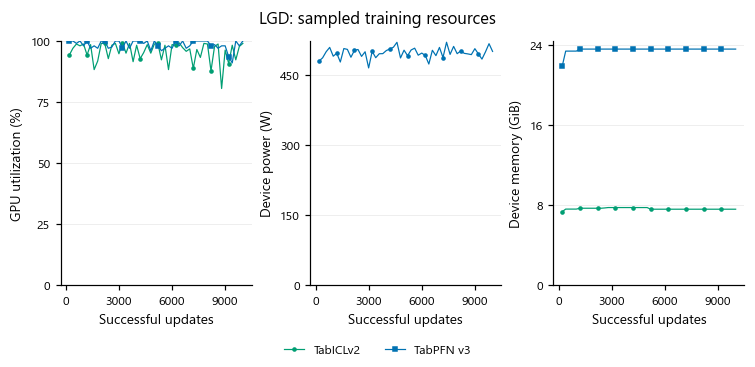

Device counters during training, summarized first by a within-trial window median, then by the median across observed trials. Recipes and adaptation modes are pooled; trial counts accompany every value. Axes start at zero, and utilization spans 0–100%, so small counter fluctuations are not magnified. Changing support can change these descriptive curves. Device samples are neither process-specific utilization nor integrated energy measurements. Missing counters remain gaps.

In [5]:
cp.show(sink, pv.plot_schedule(runs))
for run in runs:
    report.table(run.track.upper()+' optimizer parameters and training cost', ds.costs(run))
    cp.show(sink, ds.plot_resources(run))
report.add('4. Applied schedule and computational cost', 'The common schedule is shown once for PD/LGD. Device utilization and memory are sampled observations, not integrated energy. Original-weight preservation is certified by experiment-0 checks, not inferred from low drift. Final predictive comparisons belong in the results notebook.')

## Complete text summary

All displayed numerical values and captions, in section order.

In [6]:
print(report.summary(sink))

Experiment 5: DiagScale during continued pretraining

0. Evidence and scope
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.

1. Adapter recipe and training coverage
Only optimizer-selected scale deltas are updated. TabICL can retain backbone autograd flags without placing backbone tensors in the optimizer. Completed training does not establish completed evaluation.

Table: PD protocol
CSV (first column: row index)
row,setting,value
0,Optimized parameters,Zero-centered query-scale deltas only; original weights unchanged
1,Training,Cross-table CPT; target table excluded from checkpoint training
2,Grid,2 bases × 3 adapter rates × 4 dataset partitions per task; 48 trials across PD/LGD
3,Adapter rates,"0.0001, 0.001, 0.03"
4,Episode cap,8192
5,Precision,FP32; TabICL original/adapter inference both disable AMP and FA3
6,Budget,"10,000 successful updates; seed 42"
7,Regularization,A